# 07_figshare: Figshare

Datasets deposited directly by authors (2,286 search hits; journal mirrors are filed under their journal). Most usable ones come from the Flegr lab, Charles University, Prague.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/07_figshare'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** Figshare (figshare.com): datasets deposited directly by authors. Journal supplements that Springer Nature / PLOS mirror on
Figshare are filed under their journal (folders 02-06), e.g. the Colombian thyroid study is in 03_bmc_springer_nature.
Most come from the Flegr lab (Charles University, Prague), which publishes the raw data of its Toxoplasma studies.

## Helpers (curated loaders and source-specific functions)

In [2]:
import europe_datasets as eu


L = 'repo_supp/figshare/'

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### czech_slovak_cat_survey

**Cats, dogs, raw meat and Toxoplasma: online survey of Czech and Slovak adults (Flegr lab)**  
Czechia/Slovakia · Online survey, adults with a past Toxoplasma test · DOI/ID: `10.6084/m9.figshare.1585139`

Self-reported result of an earlier serological test; direct exposures (cats, raw meat, soil, water, unwashed vegetables).

In [4]:
CONFIG.append(dict(key='czech_slovak_cat_survey', title='Cats, dogs, raw meat and Toxoplasma: online survey of Czech and Slovak adults (Flegr lab)',
     doi='10.6084/m9.figshare.1585139', setting='Online survey, adults with a past Toxoplasma test', country='Czechia/Slovakia',
     source=('url', 'https://ndownloader.figshare.com/files/2372261'), file='catEpidemiology7270.xlsx', loader=eu.czech_slovak,
     note='Self-reported result of an earlier serological test; direct exposures (cats, raw meat, soil, water, unwashed vegetables).'))

### czech_personality_borrelia

**Past Toxoplasma and Borrelia infections, personality and cognition (Flegr lab)**  
Czechia · Online survey (Facebook "Guinea pigs" community) · DOI/ID: `10.6084/m9.figshare.21151075`

toxo: 2 = tested negative, 3 = tested positive (self-reported). Features are mostly personality / cognition (possible consequences).

In [5]:
CONFIG.append(dict(key='czech_personality_borrelia', title='Past Toxoplasma and Borrelia infections, personality and cognition (Flegr lab)',
     doi='10.6084/m9.figshare.21151075', setting='Online survey (Facebook "Guinea pigs" community)', country='Czechia',
     source=('local', L + '21151075/rawDataPerfToxoBorr.csv'), file='rawDataPerfToxoBorr.csv', label='toxo', pos=['3'], neg=['2'],
     note='toxo: 2 = tested negative, 3 = tested positive (self-reported). Features are mostly personality / cognition (possible consequences).'))

### czech_health_stress

**Toxoplasma and physical health, stress and anxiety (stress-coping hypothesis, Flegr lab)**  
Czechia · Online survey · DOI/ID: `10.6084/m9.figshare.25188788`

Toxo: 2 = tested negative, 3 = tested positive (self-reported).

In [6]:
CONFIG.append(dict(key='czech_health_stress', title='Toxoplasma and physical health, stress and anxiety (stress-coping hypothesis, Flegr lab)',
     doi='10.6084/m9.figshare.25188788', setting='Online survey', country='Czechia',
     source=('local', L + '25188788/jakSeMame15Ready.csv'), file='jakSeMame15Ready.csv', label='Toxo', pos=['3'], neg=['2'],
     drop=['nan'], note='Toxo: 2 = tested negative, 3 = tested positive (self-reported).'))

### czech_students_toxo_cmv_iq

**Toxoplasma and CMV vs intelligence and memory in university students**  
Czechia · Healthy university students, serologically tested · DOI/ID: `10.6084/m9.figshare.21865677`

Toxoplasma IgG measured in the lab; CMV IgG and Rh factor kept as biomarkers; cognitive scores are outcomes.

In [7]:
CONFIG.append(dict(key='czech_students_toxo_cmv_iq', title='Toxoplasma and CMV vs intelligence and memory in university students',
     doi='10.6084/m9.figshare.21865677', setting='Healthy university students, serologically tested', country='Czechia',
     source=('local', L + '21865677/toxoCMVcogn2022raw.csv'), file='toxoCMVcogn2022raw.csv', label='toxo', pos=['1'], neg=['0'],
     note='Toxoplasma IgG measured in the lab; CMV IgG and Rh factor kept as biomarkers; cognitive scores are outcomes.'))

### czech_toxo_cmv_longitudinal

**Toxoplasma and CMV: longitudinal study of cognitive change**  
Czechia · Adults re-tested after several years · DOI/ID: `10.6084/m9.figshare.32706477`

In [8]:
CONFIG.append(dict(key='czech_toxo_cmv_longitudinal', title='Toxoplasma and CMV: longitudinal study of cognitive change',
     doi='10.6084/m9.figshare.32706477', setting='Adults re-tested after several years', country='Czechia',
     source=('local', L + '32706477/Data_ToxoCMV_Longitudinal_fighare_anonym.xlsx'),
     file='Data_ToxoCMV_Longitudinal_fighare_anonym.xlsx', label='TOXO', pos=['1'], neg=['0'],
     drop=['T1_date', 'T2_date']))

### czech_sexual_partners

**Male-to-female presumed transmission of toxoplasmosis between sexual partners**  
Czechia · Couples tested together; exposure questionnaire · DOI/ID: `10.6084/m9.figshare.9198008`

0 = negative, 1 = positive (IgG levels confirm); 2-3 = unclear, excluded. Partner status removed (pattern rule); direct exposures: raw meat, garden soil, vegetables, cat breeding, number of cats.

In [9]:
CONFIG.append(dict(key='czech_sexual_partners', title='Male-to-female presumed transmission of toxoplasmosis between sexual partners',
     doi='10.6084/m9.figshare.9198008', setting='Couples tested together; exposure questionnaire', country='Czechia',
     source=('local', L + '9198008/Data_Male-to-female presumed transmission of toxoplasmosis between sexual partners.xlsx'),
     file='Data_Male-to-female presumed transmission of toxoplasmosis between sexual partners.xlsx', label='toxo', pos=['1'], neg=['0'],
     drop=['KFR', 'IgG', 'sex_transmission'],
     note='0 = negative, 1 = positive (IgG levels confirm); 2-3 = unclear, excluded. Partner status removed (pattern rule); '
          'direct exposures: raw meat, garden soil, vegetables, cat breeding, number of cats.'))

### poland_forensic_alcohol

**Latent Toxoplasma infection and excessive ethanol consumption (forensic autopsies)**  
Poland · Forensic autopsy cases · DOI/ID: `10.6084/m9.figshare.5226496`

In [10]:
CONFIG.append(dict(key='poland_forensic_alcohol', title='Latent Toxoplasma infection and excessive ethanol consumption (forensic autopsies)',
     doi='10.6084/m9.figshare.5226496', setting='Forensic autopsy cases', country='Poland',
     source=('local', L + '5226496/Database_DS.xls'), file='Database_DS.xls', sheet='Arkusz1', label='Serology results', pos=['positive'], neg=['negative'],
     drop=['Cause of death']))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [11]:
res = run(HERE, CONFIG)

czech_slovak_cat_survey            n=  1371 pos=  368 feats= 16 best AUC=0.659 (RandomForest)


czech_personality_borrelia         n=   962 pos=  210 feats= 26 best AUC=0.634 (LogReg)


czech_health_stress                n=   747 pos=  153 feats=  8 best AUC=0.652 (LogReg)


czech_students_toxo_cmv_iq         n=   556 pos=   97 feats= 29 best AUC=0.587 (XGBoost)


czech_toxo_cmv_longitudinal        n=    93 pos=   25 feats= 77 best AUC=0.406 (RandomForest)


czech_sexual_partners              n=  1433 pos=  357 feats=  9 best AUC=0.579 (LogReg)


poland_forensic_alcohol            n=   535 pos=  248 feats= 10 best AUC=0.593 (RandomForest)


In [12]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,czech_slovak_cat_survey,Czechia/Slovakia,1371,368,0.268,16,0.636,0.659,0.654,0.659,RandomForest
1,czech_personality_borrelia,Czechia,962,210,0.218,26,0.634,0.607,0.616,0.634,LogReg
2,czech_health_stress,Czechia,747,153,0.205,8,0.652,0.612,0.601,0.652,LogReg
3,czech_students_toxo_cmv_iq,Czechia,556,97,0.174,29,0.560,0.533,0.587,0.587,XGBoost
4,czech_toxo_cmv_longitudinal,Czechia,93,25,0.269,77,0.396,0.406,0.365,0.406,RandomForest
5,czech_sexual_partners,Czechia,1433,357,0.249,9,0.579,0.561,0.553,0.579,LogReg
6,poland_forensic_alcohol,Poland,535,248,0.464,10,0.547,0.593,0.548,0.593,RandomForest


## Chart

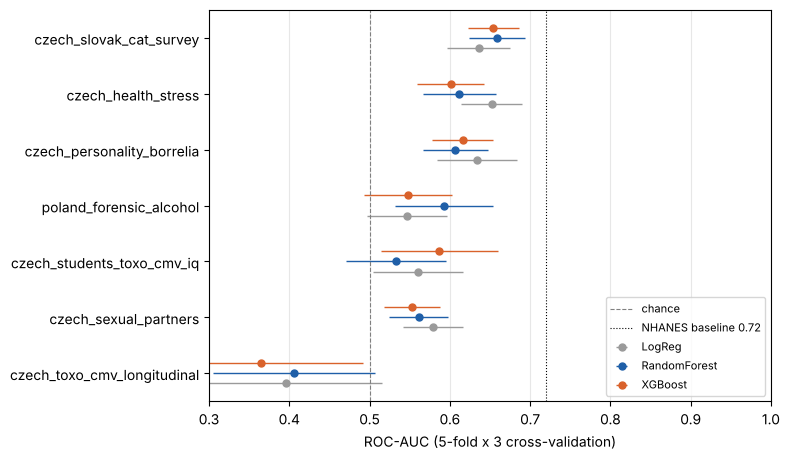

In [13]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [14]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,czech_slovak_cat_survey,,"age, male, residence_size, dogs, dog_bitten, cats, cat_b..."
1,czech_personality_borrelia,ID,"borreliosis, physSickness, mentalSickness, education, Iq..."
2,czech_health_stress,,"sex, age, livingNow, physHealthToday_1, mentHealthToday_..."
3,czech_students_toxo_cmv_iq,"ID, toxoIgGpozit","sex, age, cmv, Rh, totalIQ, totalKnowl, verbalIQ, verbal..."
4,czech_toxo_cmv_longitudinal,ID,"duration_between_periods_years, sex, T1_age, T2_age, CMV..."
5,czech_sexual_partners,"id, toxo_partner","sex, age, relationship, resid_child, raw_meat, garden_so..."
6,poland_forensic_alcohol,No,"Alcohol, Alcohol blood [promile], Alcohol urine [promile..."
